# Clustering
## Step 00: Load dataset

In [2]:
import pandas as pd

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

print("Shape:", df.shape)
df.info()
df.columns

Shape: (20573, 30)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20573 entries, 0 to 20572
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BGGId                   20573 non-null  int64  
 1   GameWeight              20573 non-null  float64
 2   MinPlayers              20573 non-null  int64  
 3   MaxPlayers              20573 non-null  int64  
 4   NumOwned                20573 non-null  int64  
 5   NumWant                 20573 non-null  int64  
 6   NumAlternates           20573 non-null  int64  
 7   NumExpansions           20573 non-null  int64  
 8   NumImplementations      20573 non-null  int64  
 9   IsReimplementation      20573 non-null  int64  
 10  Kickstarted             20573 non-null  int64  
 11  Cat:Thematic            20573 non-null  int64  
 12  Cat:Strategy            20573 non-null  int64  
 13  Cat:War                 20573 non-null  int64  
 14  Cat:Family         

Index(['BGGId', 'GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Rating', 'Age', 'AvgPlaytime', 'AgeRec',
       'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
       'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log',
       'MaxPlayers_log'],
      dtype='object')

## Step 01: Select features for clustering (choose attributes)
For this analysis we selected the attributes that describe the charateristics of the boardgames. So: all binary category features + Age, Gameweigh, MinPlayers, MaxPlayers_log, AgeRec, AvgPlaytime_log.
We clipped the extremely heavy tailed data of MaxPlayers_log and AvgPlaytime_log at the 99.5th percentile.
We standardized the continuous variables and we also applied a Bin weight of 2.0 at the categoty features to have a better distance between binary data.

In [3]:
from sklearn.preprocessing import StandardScaler
import numpy as np

categoric_cols = [
    'Kickstarted'
]

continuous_cols = [
    'Age',
    'NumOwned_log',
    'NumAlternates_log',
    'NumExpansions_log',
    'NumImplementations_log',
    'NumWant_log'
]


df2 = df.copy()

# Extremely heavy tailed data is clipped at 99.5th percentile
for col in ['NumOwned_log','NumAlternates_log','NumExpansions_log','NumImplementations_log','NumWant_log']:
    cap = df2[col].quantile(0.995)
    df2[col] = df2[col].clip(upper=cap)

scaler = StandardScaler()
X_cont = scaler.fit_transform(df2[continuous_cols].to_numpy())

# Bin weight controls the distance between binary data
BIN_WEIGHT = 2.0
X_bin = df2[categoric_cols].to_numpy() * BIN_WEIGHT

Xp = np.hstack([X_cont, X_bin])
print(Xp.shape)


(20573, 7)


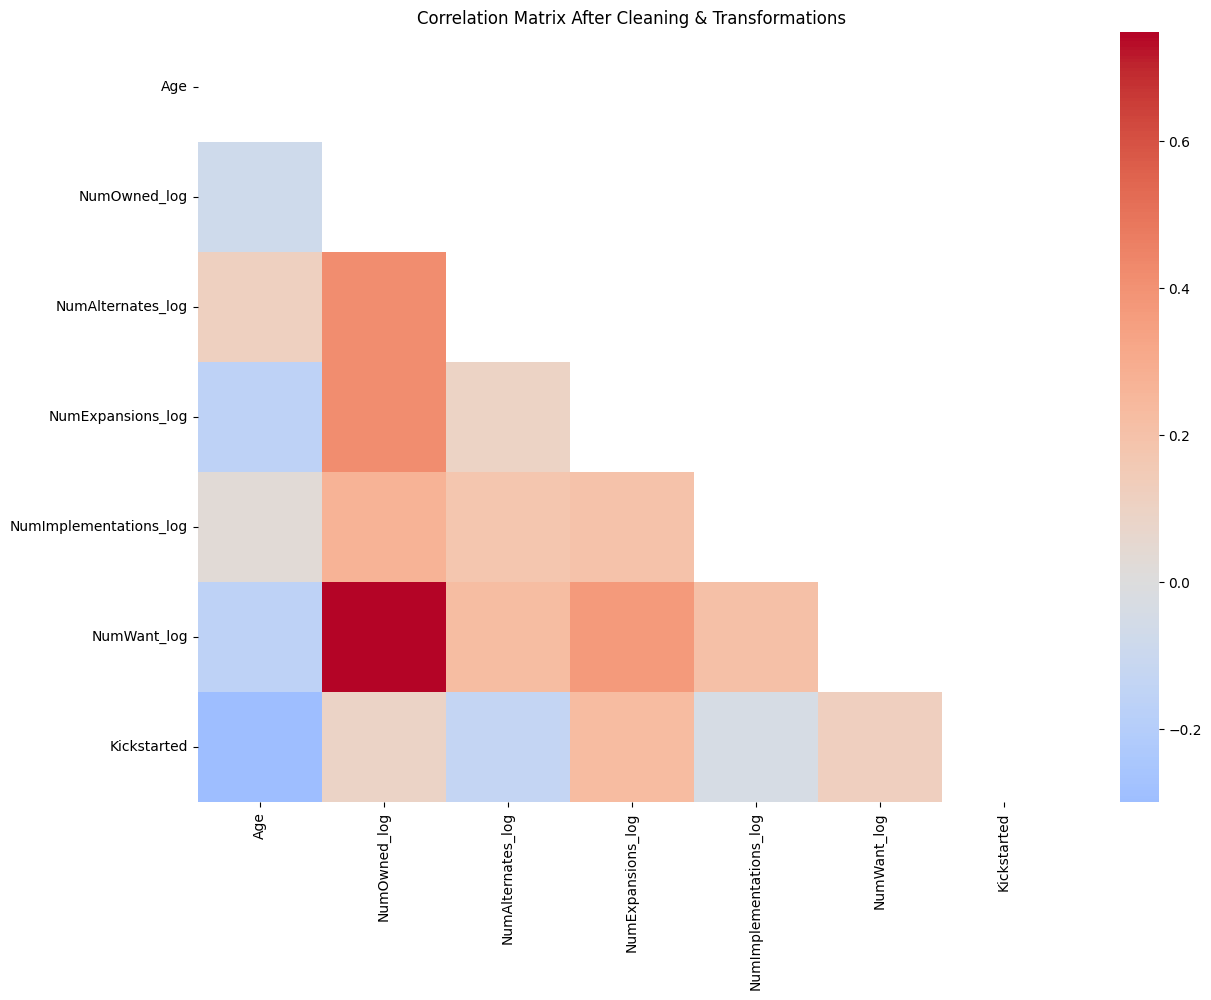

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns


test = df2[continuous_cols+categoric_cols].corr(numeric_only=True)

trimask = np.triu(np.ones_like(test, dtype=bool))

plt.figure(figsize=(14, 10))
sns.heatmap(test, cmap="coolwarm", center=0, mask=trimask)
plt.title("Correlation Matrix After Cleaning & Transformations")
plt.show()

### 1. K-Means

#### Evaluate K-Means for K = 2 to 30

To choose the right K we used Inertia (Elbow method) and the Silhouette Score.

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for k in range(2, 31):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = kmeans.fit_predict(Xp)
    
    inertia = kmeans.inertia_
    sil = silhouette_score(Xp, labels)
    
    results.append((k, inertia, sil))

df_k = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])
print(df_k)

     K        Inertia  Silhouette
0    2  102302.454830    0.293913
1    3   89704.104522    0.207914
2    4   80035.813596    0.224880
3    5   71657.653714    0.207470
4    6   64354.515343    0.244096
5    7   59298.917750    0.212217
6    8   55222.861709    0.228672
7    9   52156.952453    0.215710
8   10   49374.951000    0.219951
9   11   47053.086106    0.223424
10  12   45044.165274    0.229941
11  13   43363.382461    0.231969
12  14   41892.569391    0.205747
13  15   40574.690104    0.208005
14  16   39397.374239    0.212909
15  17   38279.041120    0.218344
16  18   37160.247930    0.222148
17  19   36237.416888    0.220219
18  20   35402.852155    0.210322
19  21   34437.520456    0.223462
20  22   33625.982682    0.211769
21  23   32811.194935    0.215842
22  24   32164.312794    0.214298
23  25   31509.461026    0.215967
24  26   31005.851191    0.214528
25  27   30447.335337    0.200790
26  28   29845.665940    0.215037
27  29   29300.874186    0.203078
28  30   28839

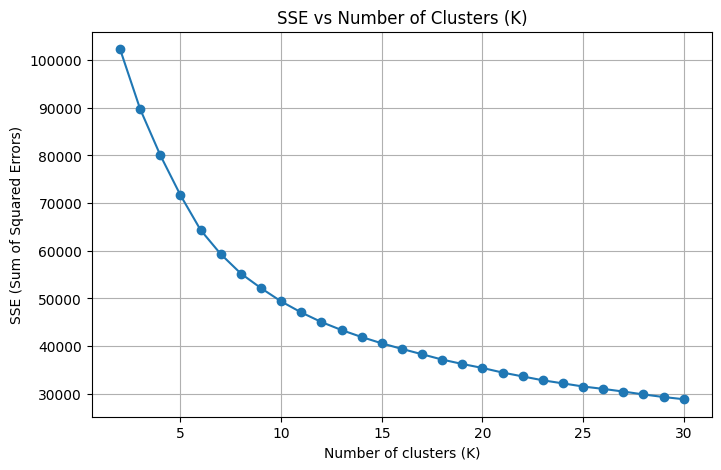

In [6]:
results_df = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(results_df["K"], results_df["Inertia"], marker='o')
plt.title("SSE vs Number of Clusters (K)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("SSE (Sum of Squared Errors)")
plt.grid(True)
plt.show()

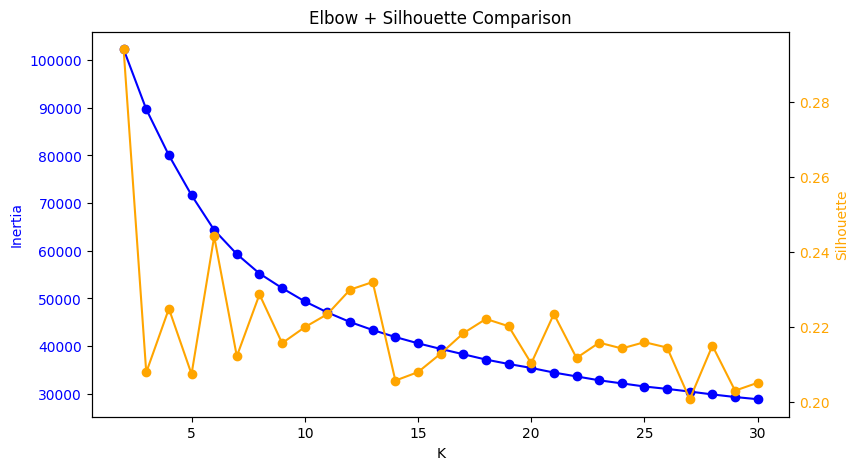

In [7]:
fig, ax1 = plt.subplots(figsize=(9,5))

ax1.set_xlabel("K")
ax1.set_ylabel("Inertia", color='blue')
ax1.plot(df_k["K"], df_k["Inertia"], marker='o', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.set_ylabel("Silhouette", color='orange')
ax2.plot(df_k["K"], df_k["Silhouette"], marker='o', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

plt.title("Elbow + Silhouette Comparison")
plt.show()

K = 8 is selected as the optimal number of clusters because it achieves the best balance between compactness and separation, supported by both inertia flattening and a higher silhouette score.

For high-dimensional real-world datasets, values between 0.15–0.25 are common. Indicates reasonable but not perfect separation. The final silhouette score of 0.21 suggests a moderate level of cohesion and separation, which is typical for large real datasets with mixed attributes, confirming that the K=8 model is appropriate and not over-segmented.

#### Fit the Final K-Means Model (K = 8)

In [8]:
from sklearn.cluster import KMeans

k_opt = 6

km = KMeans(n_clusters=k_opt, n_init=100, random_state=42)
labels = km.fit_predict(Xp)

dfc = df.copy()
dfc["cluster"] = labels

dfc["cluster"].value_counts().sort_index()

cluster
0    7678
1    3280
2    1481
3    2571
4    2783
5    2780
Name: count, dtype: int64

In [9]:

import numpy as np


# Medians for continuous, means for binaries (= prevalence)
continuous_profile = dfc.groupby("cluster")[continuous_cols].median(numeric_only=True)
binary_profile  = dfc.groupby("cluster")[categoric_cols].mean(numeric_only=True)

# Back-transform logs for interpretability
continuous_profile["NumOwned_med"] = np.expm1(continuous_profile["NumOwned_log"])
continuous_profile["NumAlternates_med"]  = np.expm1(continuous_profile["NumAlternates_log"])
continuous_profile["NumExpansions_med"] = np.expm1(continuous_profile["NumExpansions_log"])
continuous_profile["NumImplementations_med"]  = np.expm1(continuous_profile["NumImplementations_log"])
continuous_profile["NumWant_med"] = np.expm1(continuous_profile["NumWant_log"])

continuous_profile = continuous_profile.drop(columns=["NumOwned_log","NumAlternates_log","NumExpansions_log","NumImplementations_log","NumWant_log"])

clusters_sizes = dfc["cluster"].value_counts().sort_index()
profile = continuous_profile.join(binary_profile)
profile.insert(0, "n", clusters_sizes)
profile.insert(1, "pct", (clusters_sizes / len(dfc)).round(3))


print(profile)


            n    pct   Age  NumOwned_med  NumAlternates_med  \
cluster                                                       
0        7678  0.373  14.0    192.000000                0.0   
1        3280  0.159  12.0   1703.499927                2.0   
2        1481  0.072  11.0   4394.000000                2.0   
3        2571  0.125   8.0    355.000000                0.0   
4        2783  0.135  15.0    393.000000                0.0   
5        2780  0.135  43.0    261.000000                0.0   

         NumExpansions_med  NumImplementations_med  NumWant_med  Kickstarted  
cluster                                                                       
0                      0.0                     0.0          4.0     0.000000  
1                      0.0                     0.0         55.0     0.037500  
2                      7.0                     1.0        125.0     0.325456  
3                      0.0                     0.0         11.0     1.000000  
4                    

**To interpret the clusters, we transformed the logarithmic variables back to their original scale and used the median for continuous variables and the mean for binary variables.**

### Cluster  0

- 7,678 records (37.3%)
- Age ≈ 14 years
- NumOwned ≈ 192
- NumWant ≈ 4
- Minimal expansions, alternates, and implementations
- No Kickstarter presence (0%)

Traditional catalog with limited engagement. This cluster represents the largest segment: mid-age games from conventional publishing that have achieved modest ownership but generate minimal current interest, reflecting either saturated niche markets or titles that never broke through to wider audiences.


### Cluster  1

- 3,280 records (15.9%)
- Age ≈ 12 years
- NumOwned ≈ 1,704
- NumWant ≈ 55
- NumAlternates ≈ 2
- Minimal Kickstarter presence (4%)

Successful mid-market titles with moderate franchise development. This cluster captures games that have achieved substantial ownership and sustained demand, spawning alternate versions that indicate proven commercial viability and ongoing publisher investment.


### Cluster  2

- 1,481 records (7.2%)
- Age ≈ 11 years
- NumOwned ≈ 4,394
- NumWant ≈ 125
- NumExpansions ≈ 7, NumAlternates ≈ 2, NumImplementations ≈ 1
- 33% are Kickstarted

Premium titles with extensive content ecosystems. This cluster represents highly successful games with exceptional ownership penetration, substantial expansion development, and strong ongoing demand, with crowdfunding playing a significant role in their release strategy.

### Cluster  3

- 2,571 records (12.5%)
- Age ≈ 8 years
- NumOwned ≈ 355
- NumWant ≈ 11
- Minimal expansions, alternates, and implementations
- All games are Kickstarted (100%)

Recent crowdfunding releases building market presence. This cluster captures newer Kickstarter-exclusive titles that have achieved moderate ownership and maintain modest interest levels, representing the contemporary crowdfunded segment still establishing their market position.


### Cluster  4

- 2,783 records (13.5%)
- Age ≈ 15 years
- NumOwned ≈ 393
- NumWant ≈ 11
- NumImplementations ≈ 1
- Minimal Kickstarter presence (2%)

Established designs with mechanical legacy. This cluster represents older traditionally-published games that have spawned implementations of their core systems, maintaining steady ownership and interest without relying on expansion content or crowdfunding.


### Cluster  5

- 2,780 records (13.5%)
- Age ≈ 43 years
- NumOwned ≈ 261
- NumWant ≈ 6
- Minimal expansions, alternates, and implementations
- Virtually no Kickstarter presence (0.2%)

Historical catalog from the pre-modern era. This cluster captures significantly older games that maintain modest ownership despite their age, representing vintage titles, classic designs, or regional games from earlier publishing eras that retain collector and historical interest.


## PCA plot (post-clustering)


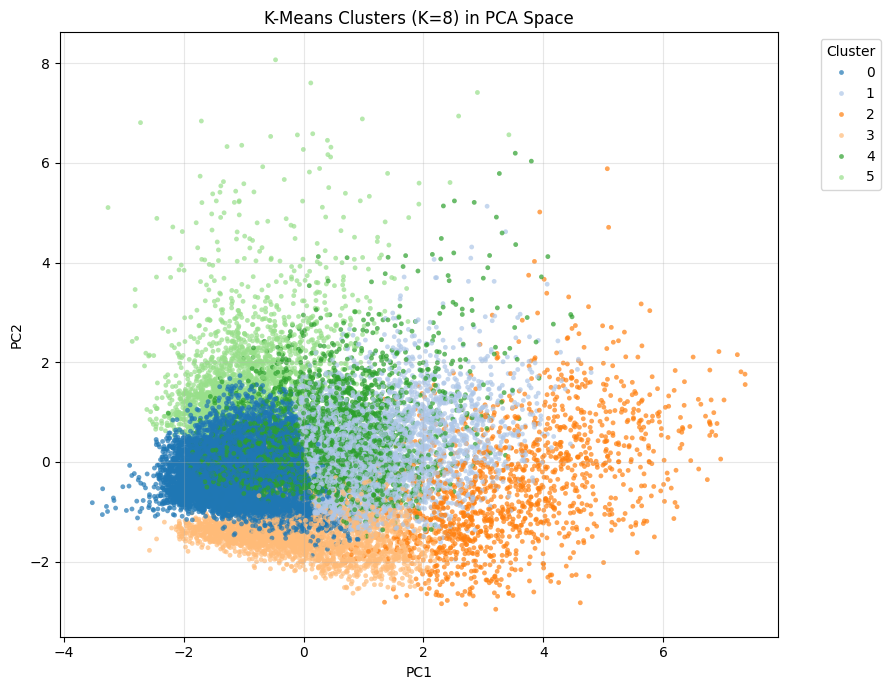

Explained variance by PC1 and PC2: [0.365 0.195]


In [10]:
from sklearn.decomposition import PCA

Xp = Xp[dfc.index]  # funziona se Xp è numpy array con stesso ordine di dfc

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(Xp)

df_pca = dfc.copy()
df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]

palette = sns.color_palette("tab20", n_colors=df_pca["cluster"].nunique())

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette=palette,
    s=12,
    alpha=0.7,
    linewidth=0
)
plt.title("K-Means Clusters (K=8) in PCA Space")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Explained variance by PC1 and PC2:",
      np.round(pca.explained_variance_ratio_, 3))


**The PCA visualization shows partial but not complete separation between clusters, which is expected given dimensionality reduction from 14 to 2 components.**

## Post-Clustering
This part is to analyze the question: how are Low / Medium / High rated games distributed across clusters? It allows us to see whether certain clusters are dominated by highly rated games or contain mostly low-rated ones.

The following graph shows percentages of Ratings across all clusters.

<Figure size 900x500 with 0 Axes>

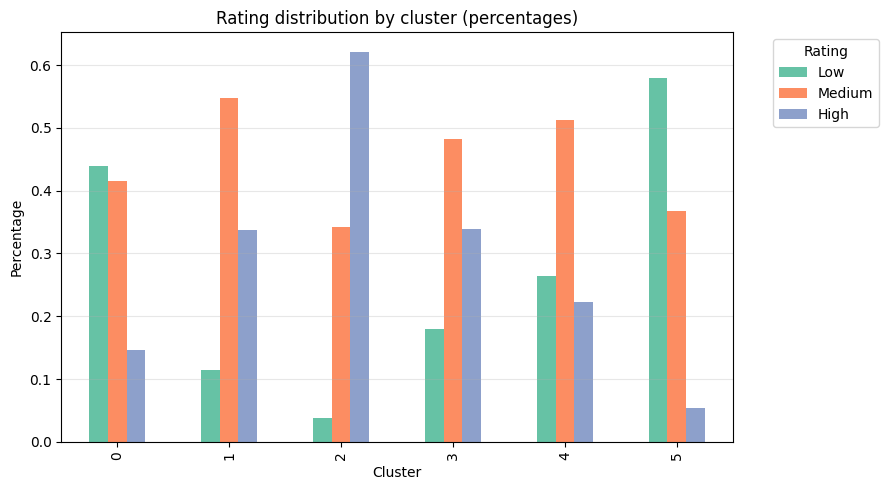

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

rating_proportions = (
    dfc.groupby("cluster")["Rating"]
       .value_counts(normalize=True)
       .unstack(fill_value=0)
       .round(3)
)

rating_order = ['Low', 'Medium', 'High']
rating_proportions = rating_proportions[[col for col in rating_order if col in rating_proportions.columns]]

plt.figure(figsize=(9, 5))

rating_proportions.plot(kind='bar', figsize=(9, 5), color=sns.color_palette("Set2"))
plt.title("Rating distribution by cluster (percentages)")
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



The following graph shows average rating per cluster compared to the average.

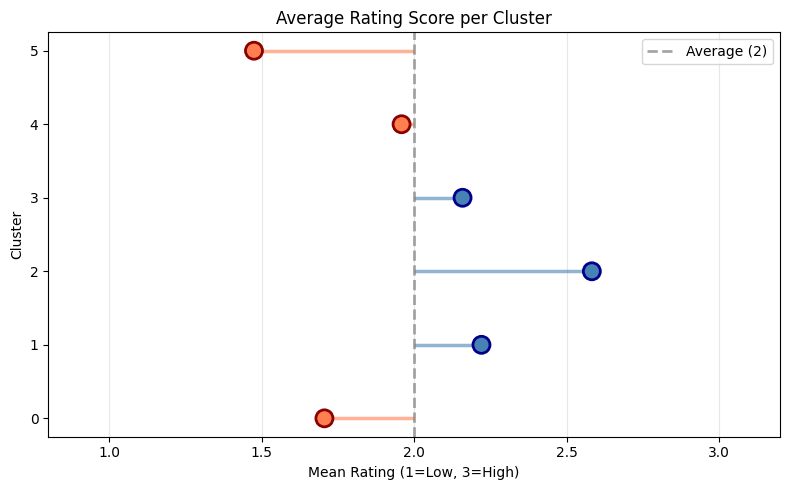

In [12]:
import matplotlib.pyplot as plt

rating_map = {"Low": 1, "Medium": 2, "High": 3}

dfc["Rating_num"] = dfc["Rating"].map(rating_map)

mean_rating_per_cluster = (
    dfc.groupby("cluster")["Rating_num"]
       .mean()
       .round(3)
)

plt.figure(figsize=(8, 5))

# Calcola quali cluster sono sopra/sotto la media di 2
colors = ['steelblue' if x > 2 else 'coral' for x in mean_rating_per_cluster.values]
edge_colors = ['darkblue' if x > 2 else 'darkred' for x in mean_rating_per_cluster.values]

# Linee orizzontali - partono da 2 (la media)
for i, (idx, val) in enumerate(mean_rating_per_cluster.items()):
    if val > 2:
        # Sopra la media: va a destra
        plt.hlines(y=i, xmin=2, xmax=val, color='steelblue', alpha=0.6, linewidth=2.5)
    else:
        # Sotto la media: va a sinistra
        plt.hlines(y=i, xmin=val, xmax=2, color='coral', alpha=0.6, linewidth=2.5)

# Punti alla fine delle linee
plt.scatter(
    mean_rating_per_cluster.values, 
    range(len(mean_rating_per_cluster)), 
    s=150, 
    c=colors,
    edgecolors=edge_colors,
    linewidth=2,
    zorder=3
)

# Configurazione assi e labels
plt.yticks(range(len(mean_rating_per_cluster)), mean_rating_per_cluster.index)
plt.xlim(0.8, 3.2)
plt.xlabel("Mean Rating (1=Low, 3=High)")
plt.ylabel("Cluster")
plt.title("Average Rating Score per Cluster")

# Linea verticale per la media a 2
plt.axvline(x=2, color='gray', linestyle='--', alpha=0.7, linewidth=2, label='Average (2)')

plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Final Note
The rating-based analyses confirm that the clustering identifies distinct groups of board games that differ systematically in perceived quality. Even though ratings were excluded from the clustering process, they are a strong external validation signal, reinforcing the robustness and interpretability of the clustering results.

In [13]:
df_kmeans_export = dfc.copy()

df_kmeans_export[["BGGId", "cluster"]].to_csv(
    "kmeans_market_distribution.csv",
    index=False
)


In [15]:
dfc

,BGGId,GameWeight,MinPlayers,MaxPlayers,NumOwned,NumWant,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,...,AgeRec,NumOwned_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumWant_log,AvgPlaytime_log,MaxPlayers_log,cluster,Rating_num
0,17755,1.0000,2,6,145,1,18,0,2,1,...,5.500000,4.983607,2.944439,0.000000,1.098612,0.693147,3.044522,1.945910,6,1
1,14765,2.6000,4,4,25,2,0,0,0,0,...,8.308707,3.258097,0.000000,0.000000,0.000000,1.098612,2.397895,1.609438,6,3
2,17183,2.0000,2,4,20,0,9,0,0,0,...,11.000000,3.044522,2.302585,0.000000,0.000000,0.000000,4.110874,1.609438,6,2
3,2294,1.1379,1,8,1848,5,2,0,0,0,...,7.166667,7.522400,1.098612,0.000000,0.000000,1.791759,3.044522,2.197225,6,1
4,140,1.1582,3,8,15115,75,19,1,1,1,...,7.421053,9.623509,2.995732,0.693147,0.693147,4.330733,4.110874,2.197225,6,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20568,310192,2.0455,1,5,2386,74,0,1,0,0,...,7.416667,7.777793,0.000000,0.693147,0.000000,4.317488,3.258097,1.791759,3,3
20569,319579,1.1111,1,5,761,131,0,0,0,0,...,7.025166,6.635947,0.000000,0.000000,0.000000,4.882802,3.258097,1.791759,4,3
20570,307386,2.5000,1,4,849,18,3,1,0,0,...,10.135379,6.745236,1.386294,0.693147,0.000000,2.944439,4.226834,1.609438,5,3
20571,322560,2.0000,1,2,204,20,0,0,1,1,...,12.000000,5.323010,0.000000,0.000000,0.693147,3.044522,3.157000,1.098612,5,2
